# Example: Closed and Open Wolfram Markets
In this example, we run a rule switch in a closed market, in which the same traders stay on the grid, and in an open market, in which traders leave and new players take their places. We then let a fraction of the players follow a contrarian rule, and compare the share price and the filled orders of the markets.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Compare a closed market with an open market:__ Run a rule switch in a market whose traders never change and in a market whose players come and go, and compare the share price and the number of filled orders.
> * __Add contrarian players:__ Read the table of a contrarian rule, let a fraction of the players follow the rule, and compare the grid, the share price, and the filled orders with and without the contrarian players.
> * __Find how many contrarian players an open market needs:__ Repeat the rule switch for several fractions of contrarian players and many starting markets, and compare the share price of the switched market with its control.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file
import VLQuantitativeFinancePackage.WolframMarkets as WM; # the Wolfram market simulator, qualified so its names stay separate

For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Constants
Next, let's set the constants. The market uses a deep dealer and active edge traders, who buy when the share price is well below its recent average and sell when it is well above it.

Each step lasts `Δt` years, and the default is one minute of trading. At each step, the dealer's share price also changes by a random amount, the __noise__, with annualized volatility `σ_S`.

Change the parameters and run the cells again. Every task runs live and follows the constants:

In [2]:
# the rules -
baseline_rule = 19280; # rule number that every interior trader follows before the switch, from 0 to 19682; the default is the baseline rule of the lecture
switch_rule = 19286; # rule number that the switching traders follow after the switch; the default is the switch rule of the lecture
contrarian_rule = 377; # rule number that the contrarian players follow; Rule 377 is Buy for sums 6 to 8, Hold for sums 3 to 5, and Sell for sums 0 to 2

# Case: a bubble that pops. Under Rule 19287, nearly every trader intends to buy and the share price rises.
# Rule 19341 changes one entry of Rule 19287: at sum 3, a trader sells instead of buys.
# Remove the # from the two lines below to run this case -
# baseline_rule = 19287;
# switch_rule = 19341;

# the players -
refresh_rate = 0.001; # fraction of interior traders that a new player replaces at each step
contrarian_fraction = 0.25; # fraction of the players that follow contrarian_rule

# the market -
L = 64; # grid size (L × L traders, including the edge)
f = 0.25; # fraction of interior traders that switch to switch_rule
h = 100.0; # dealer depth; a small value (for example 1.0) makes the price move a long way for a given net order
boundary_mode = :endogenous; # edge traders: :endogenous (active), :hold (held), or :random (random draws)
random_probabilities = (1/3, 1/3, 1/3); # probabilities of (Buy, Hold, Sell) for :random edge traders; ignored otherwise
seed = 1; # starting market; each seed gives a different random start
t_pre = 1000; # steps before the switch
t_post = 3000; # steps after the switch
steps_to_visualize = [t_pre, t_pre + 100, t_pre + 200, t_pre + 300, t_pre + 500, t_pre + t_post]; # six steps at which we save and draw the grid, in order
first_step_to_plot = 100; # first step shown in the plots; the earlier steps are the startup from the random starting market

# the time step and the noise in the dealer's share price -
Δt = 1/(252*390); # length of one step (years), one minute of a 390-minute trading day
σ_S = 0.40; # annualized volatility of the noise in the dealer's share price (1/√yr); the noise added in one step has standard deviation σ_S√Δt, and 0.0 gives no noise

# the starting markets and the fractions of contrarian players in Task 3 -
L_small = 32; # a smaller grid, so that the runs of Task 3 take a few seconds
seeds = 1:10; # the starting markets
contrarian_fractions = collect(0.0:0.05:0.50); # fractions of the players that follow contrarian_rule

# colors and names used in every plot -
color_switched = :red; # the switched market
color_control = :navy; # the control market, which never switches
color_contrarian = :green4; # the switched market with contrarian players
intention_colors = [parse(Colorant, "#0072B2"), parse(Colorant, "#AAAAAA"), parse(Colorant, "#D55E00")]; # Buy is blue, Hold is gray, Sell is orange
intention_names = ["Buy", "Hold", "Sell"];

___

## Task 1: Compare a Closed Market with an Open Market
In this task, we run a rule switch in a closed market and in an open market, and compare the share price and the number of filled orders.

In a __rule switch__, all interior traders follow the rule `baseline_rule` until the switch step, and then a fraction $f$ of them change to the rule `switch_rule`. The __control__ shares the history of the switched market and never switches. In a __closed market__, the same traders stay on the grid for the whole run.

We can also treat the grid as a viewport on a larger __open market__. At each step, each interior trader leaves the viewport with probability `refresh_rate`, and a __new player__ takes its place. The new player starts with the cash and shares that every trader had at step `0`, and takes over the intention and the rule of the trader it replaced.

A trader can buy only with the cash it holds and can sell only the shares it holds, and the dealer fills no other orders. A market __freezes__ when its traders run out of cash or shares and the dealer fills few orders.

The `run_viewport_rule_switch(...)` function in `src/Helper.jl` runs a switched market and its control. We store the two markets of the closed market in the `closed_market::NamedTuple` variable, and the two markets of the open market in the `open_market::NamedTuple` variable:

In [3]:
(closed_market, open_market) = let

    # the random-edge probabilities only matter for :random edge traders -
    kw = NamedTuple();
    if boundary_mode == :random
        kw = (random_edge_probabilities = random_probabilities,);
    end

    # run the closed market: no trader leaves, and no player follows the contrarian rule -
    closed = run_viewport_rule_switch(; baseline_rule = baseline_rule, switch_rule = switch_rule, contrarian_rule = contrarian_rule, contrarian_fraction = 0.0,
        refresh_rate = 0.0, L = L, f = f, h = h, seed = seed, boundary_mode = boundary_mode, σ_S = σ_S, Δt = Δt, t_pre = t_pre, t_post = t_post,
        snapshot_steps = steps_to_visualize, kw...);

    # run the open market: players come and go at the refresh rate, and no player follows the contrarian rule -
    opened = run_viewport_rule_switch(; baseline_rule = baseline_rule, switch_rule = switch_rule, contrarian_rule = contrarian_rule, contrarian_fraction = 0.0,
        refresh_rate = refresh_rate, L = L, f = f, h = h, seed = seed, boundary_mode = boundary_mode, σ_S = σ_S, Δt = Δt, t_pre = t_pre, t_post = t_post,
        snapshot_steps = steps_to_visualize, kw...);

    # checks -
    @assert refresh_rate > 0.0 "the open market needs a positive refresh rate"
    @assert length(closed.switched.prices) == t_pre + t_post + 1 "one price for each step, including step 0"
    @assert length(opened.switched.prices) == t_pre + t_post + 1 "one price for each step, including step 0"

    # return -
    (closed, opened)
end;

`Unhide` the code block below to see how we plotted the number of filled orders and the share price at each step, for the two switched markets and their controls. The dashed lines are the closed market, and the solid lines are the open market.

Does the open market keep trading after the switch?

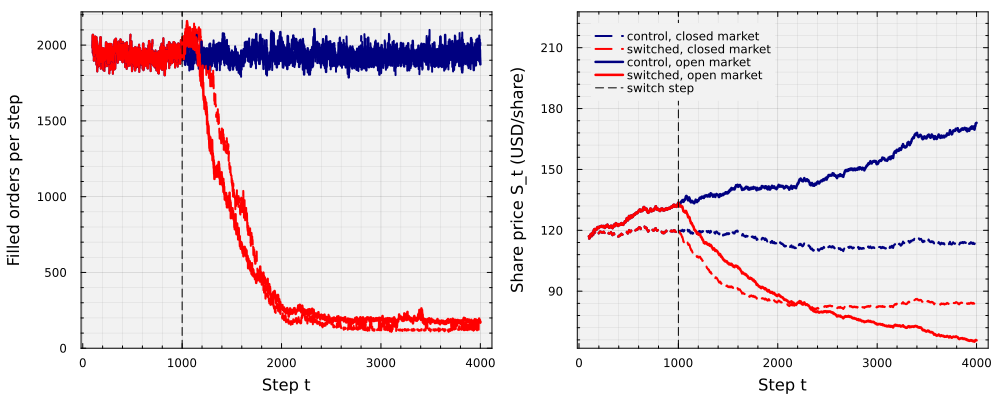

In [4]:
let

    # initialize: the steps we plot, and their positions in the saved share prices (step 0 is at position 1) -
    steps_to_plot = max(first_step_to_plot, 1):(t_pre + t_post);
    positions = steps_to_plot .+ 1;

    # count the filled orders at each step: the Buy orders plus the Sell orders that the dealer filled (step t is at position t) -
    filled_closed_control = closed_market.control.executed_buys[steps_to_plot] .+ closed_market.control.executed_sells[steps_to_plot];
    filled_closed_switched = closed_market.switched.executed_buys[steps_to_plot] .+ closed_market.switched.executed_sells[steps_to_plot];
    filled_open_control = open_market.control.executed_buys[steps_to_plot] .+ open_market.control.executed_sells[steps_to_plot];
    filled_open_switched = open_market.switched.executed_buys[steps_to_plot] .+ open_market.switched.executed_sells[steps_to_plot];

    # left panel: the filled orders in the closed market (dashed lines) and in the open market (solid lines) -
    p_orders = plot(steps_to_plot, filled_closed_control, lw = 2, c = color_control, ls = :dash, label = "",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true);
    plot!(p_orders, steps_to_plot, filled_closed_switched, lw = 2, c = color_switched, ls = :dash, label = "");
    plot!(p_orders, steps_to_plot, filled_open_control, lw = 2.5, c = color_control, label = "");
    plot!(p_orders, steps_to_plot, filled_open_switched, lw = 2.5, c = color_switched, label = "");
    vline!(p_orders, [t_pre], lw = 1, c = :black, ls = :dash, label = "");
    ylims!(p_orders, 0, ylims(p_orders)[2]); # start the axis at zero filled orders
    xlabel!(p_orders, "Step t", fontsize = 18);
    ylabel!(p_orders, "Filled orders per step", fontsize = 18);

    # right panel: the share price that the dealer quotes; the legend names the lines of both panels -
    p_price = plot(steps_to_plot, closed_market.control.prices[positions], lw = 2, c = color_control, ls = :dash, label = "control, closed market",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topleft);
    plot!(p_price, steps_to_plot, closed_market.switched.prices[positions], lw = 2, c = color_switched, ls = :dash, label = "switched, closed market");
    plot!(p_price, steps_to_plot, open_market.control.prices[positions], lw = 2.5, c = color_control, label = "control, open market");
    plot!(p_price, steps_to_plot, open_market.switched.prices[positions], lw = 2.5, c = color_switched, label = "switched, open market");
    vline!(p_price, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");
    (y_low, y_high) = ylims(p_price);
    ylims!(p_price, y_low, y_high + 0.45*(y_high - y_low)); # leave room for the legend
    xlabel!(p_price, "Step t", fontsize = 18);
    ylabel!(p_price, "Share price S_t (USD/share)", fontsize = 18);

    # show the two panels side by side -
    plot(p_orders, p_price, layout = (1, 2), size = (1000, 400), bottom_margin = 5Plots.mm, left_margin = 5Plots.mm)
end

In the closed market, the traders who share an intention run out of cash or shares, the dealer fills few orders, and the share price levels off.

In the open market, the new players bring new cash and new shares at every step, and the share price keeps moving. The new players follow the same rules as the traders they replaced, and their orders push the share price in the same direction. The number of filled orders after the switch grows with `refresh_rate`.

___

## Task 2: Add Contrarian Players
In this task, we let a fraction of the players in the open market follow a contrarian rule, and compare the grid, the share price, and the filled orders with and without the contrarian players.

A __contrarian__ player acts against its neighbors: it buys when most of its neighbors intend to sell, and sells when most of its neighbors intend to buy. The contrarian players follow the rule `contrarian_rule` in place of the baseline rule and the switch rule.

[The rule_table(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/) returns the nine entries of a rule number, ordered from sum `0` to sum `8`. We store the entries of the baseline rule in the `baseline_entries::Vector{Int64}` variable, and the entries of the contrarian rule in the `contrarian_entries::Vector{Int64}` variable:

In [5]:
(baseline_entries, contrarian_entries) = let

    # get the nine entries of each rule: table[c + 1] is the next intention for neighbor sum c -
    baseline_table = WM.rule_table(baseline_rule);
    contrarian_table = WM.rule_table(contrarian_rule);
    println("Rule $(baseline_rule) in base 3, from sum 8 down to sum 0: $(join(reverse(baseline_table)))");
    println("Rule $(contrarian_rule) in base 3, from sum 8 down to sum 0: $(join(reverse(contrarian_table)))");

    # checks -
    @assert length(baseline_table) == 9 "one entry for each neighbor sum from 0 to 8"
    @assert length(contrarian_table) == 9 "one entry for each neighbor sum from 0 to 8"

    # return -
    (baseline_table, contrarian_table)
end;

Rule 19280 in base 3, from sum 8 down to sum 0: 222110002
Rule 377 in base 3, from sum 8 down to sum 0: 000111222


`Unhide` the code block below to see how we drew the two rule tables with the `plot_rule(...)` helper in `src/Helper.jl`. Each tile shows the next intention of a trader for one sum of its neighbors' intentions, from sum `8` (four Sell neighbors) on the left to sum `0` (four Buy neighbors) on the right.

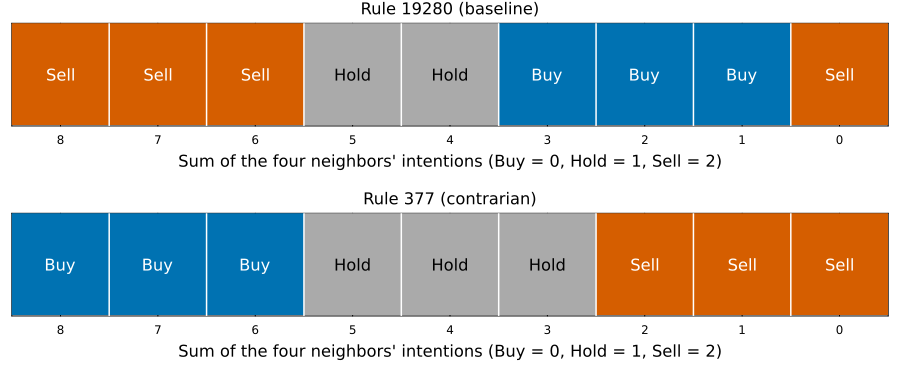

In [6]:
let

    # draw the table of each rule: sum 8 on the left, sum 0 on the right -
    p_baseline = plot_rule(baseline_entries; colors = intention_colors, names = intention_names, title_text = "Rule $(baseline_rule) (baseline)");
    p_contrarian = plot_rule(contrarian_entries; colors = intention_colors, names = intention_names, title_text = "Rule $(contrarian_rule) (contrarian)");

    # show the baseline rule on top and the contrarian rule below it -
    plot(p_baseline, p_contrarian, layout = (2, 1), size = (900, 380))
end

A fraction `contrarian_fraction` of the starting traders, and of the new players, follow the contrarian rule. Every other setting is the same as in the open market of Task 1.

We run the open market again with the contrarian players, and store the switched market and its control in the `contrarian_market::NamedTuple` variable:

In [7]:
contrarian_market = let

    # the random-edge probabilities only matter for :random edge traders -
    kw = NamedTuple();
    if boundary_mode == :random
        kw = (random_edge_probabilities = random_probabilities,);
    end

    # run the open market with contrarian players -
    t_run = @elapsed pair = run_viewport_rule_switch(; baseline_rule = baseline_rule, switch_rule = switch_rule, contrarian_rule = contrarian_rule,
        contrarian_fraction = contrarian_fraction, refresh_rate = refresh_rate, L = L, f = f, h = h, seed = seed, boundary_mode = boundary_mode,
        σ_S = σ_S, Δt = Δt, t_pre = t_pre, t_post = t_post, snapshot_steps = steps_to_visualize, kw...);
    println("run time: $(round(t_run; digits = 1)) seconds");

    # checks -
    @assert length(pair.switched.prices) == t_pre + t_post + 1 "one price for each step, including step 0"

    # return -
    pair
end;

run time: 0.6 seconds


`Unhide` the code block below to see how we plotted the Sell fraction and the share price of the switched market, with and without the contrarian players. The __Sell fraction__ is the fraction of interior traders who intend to sell.

Does the share price still fall after the switch?

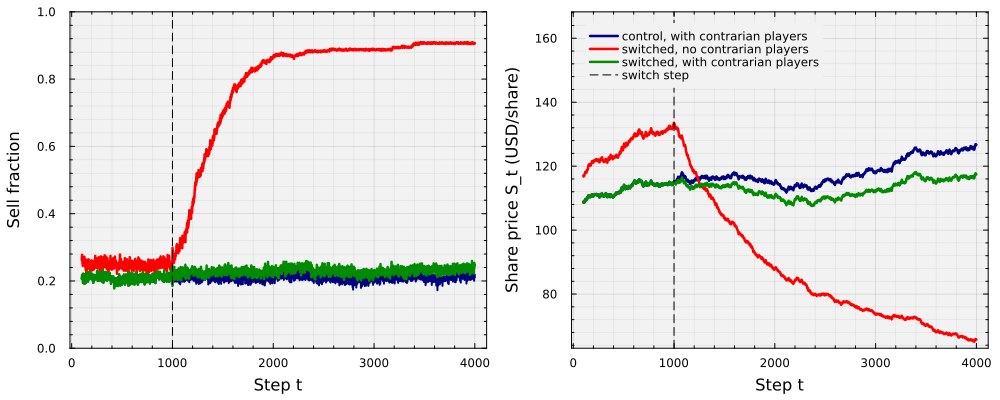

In [8]:
let

    # initialize: the steps we plot, and their positions in the saved series (step 0 is at position 1) -
    steps_to_plot = first_step_to_plot:(t_pre + t_post);
    positions = (first_step_to_plot + 1):(t_pre + t_post + 1);

    # left panel: the fraction of interior traders who intend to sell -
    p_sell = plot(steps_to_plot, contrarian_market.control.sell_fraction[positions], lw = 2, c = color_control, label = "",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, ylims = (0.0, 1.0));
    plot!(p_sell, steps_to_plot, open_market.switched.sell_fraction[positions], lw = 2.5, c = color_switched, label = "");
    plot!(p_sell, steps_to_plot, contrarian_market.switched.sell_fraction[positions], lw = 2.5, c = color_contrarian, label = "");
    vline!(p_sell, [t_pre], lw = 1, c = :black, ls = :dash, label = "");
    xlabel!(p_sell, "Step t", fontsize = 18);
    ylabel!(p_sell, "Sell fraction", fontsize = 18);

    # right panel: the share price that the dealer quotes; the legend names the lines of both panels -
    p_price = plot(steps_to_plot, contrarian_market.control.prices[positions], lw = 2.5, c = color_control, label = "control, with contrarian players",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topleft);
    plot!(p_price, steps_to_plot, open_market.switched.prices[positions], lw = 2.5, c = color_switched, label = "switched, no contrarian players");
    plot!(p_price, steps_to_plot, contrarian_market.switched.prices[positions], lw = 2.5, c = color_contrarian, label = "switched, with contrarian players");
    vline!(p_price, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");
    (y_low, y_high) = ylims(p_price);
    ylims!(p_price, y_low, y_high + 0.45*(y_high - y_low)); # leave room for the legend
    xlabel!(p_price, "Step t", fontsize = 18);
    ylabel!(p_price, "Share price S_t (USD/share)", fontsize = 18);

    # show the two panels side by side -
    plot(p_sell, p_price, layout = (1, 2), size = (1000, 400), bottom_margin = 5Plots.mm, left_margin = 5Plots.mm)
end

After the switch, the contrarian players next to a group of sellers intend to buy. They take the other side of the Sell orders, and their neighbors read a Buy intention in place of a Sell intention.

Next, let's look at the grid of the switched market at the steps in `steps_to_visualize`. Each tile is one interior trader: Buy is blue, Hold is gray, and Sell is orange. `Unhide` the code block below to see how we drew the grids with the `plot_grid(...)` helper in `src/Helper.jl`.

Where does the Sell intention stop?

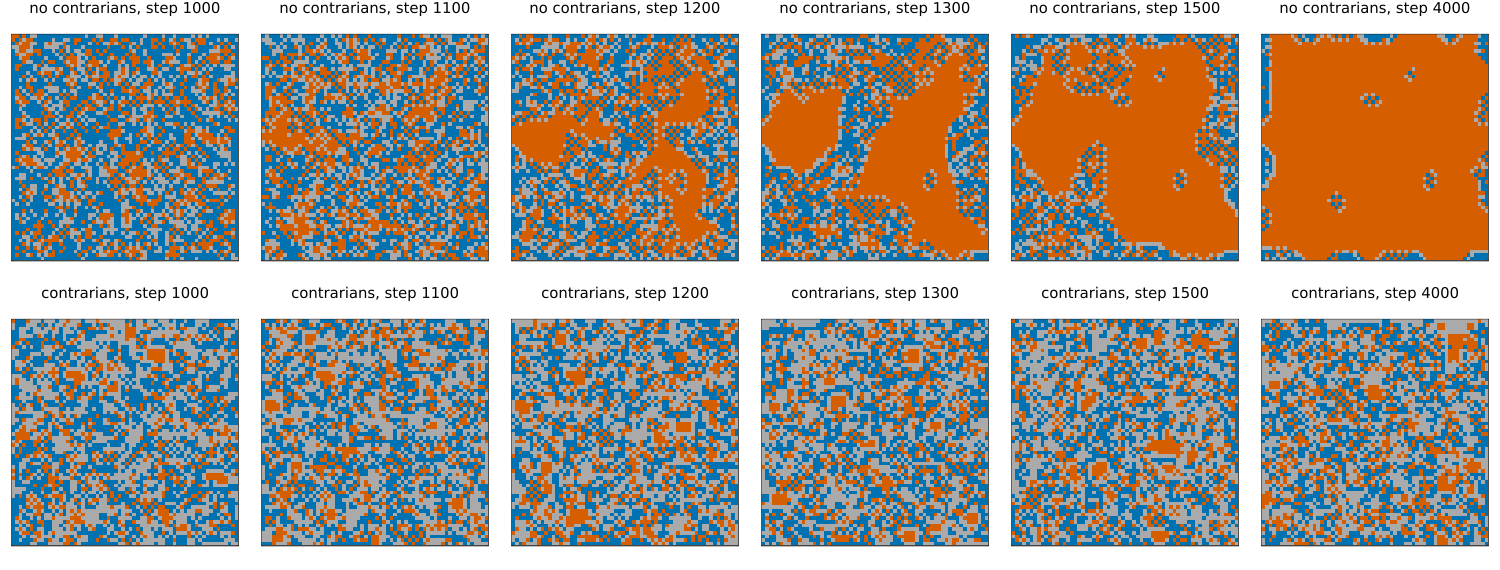

In [9]:
let

    # draw the top row: the switched open market of Task 1, which has no contrarian players -
    panels = [];
    for t ∈ steps_to_visualize
        push!(panels, plot_grid(open_market.switched.frames[t]; colors = intention_colors, title_text = "no contrarians, step $(t)"));
    end

    # draw the bottom row: the switched market with contrarian players at the same steps -
    for t ∈ steps_to_visualize
        push!(panels, plot_grid(contrarian_market.switched.frames[t]; colors = intention_colors, title_text = "contrarians, step $(t)"));
    end

    # show the two rows: the layout fills the top row first -
    number_of_steps = length(steps_to_visualize);
    plot(panels..., layout = (2, number_of_steps), size = (250*number_of_steps, 570), margin = 1Plots.mm)
end

The two rows start from different grids at the switch step, because the contrarian players have been in the bottom market since step `0`.

`Unhide` the code block below to see how we plotted the number of filled orders at each step in three switched markets: the closed market, the open market, and the open market with contrarian players.

In which market does the dealer keep filling orders after the switch?

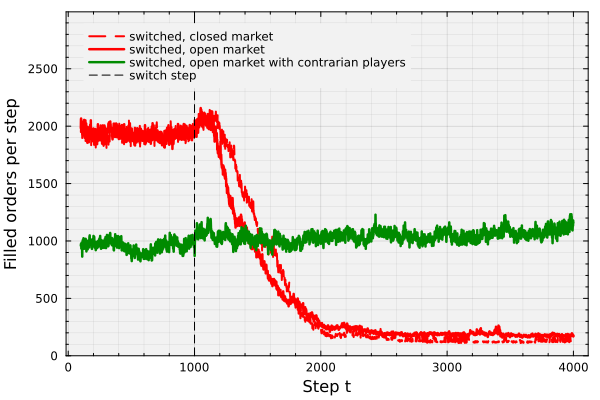

In [10]:
let

    # initialize: the steps we plot; there is one count for each step after step 0, and step t is at position t -
    steps_to_plot = max(first_step_to_plot, 1):(t_pre + t_post);

    # count the filled orders at each step: the Buy orders plus the Sell orders that the dealer filled -
    filled_closed = closed_market.switched.executed_buys[steps_to_plot] .+ closed_market.switched.executed_sells[steps_to_plot];
    filled_open = open_market.switched.executed_buys[steps_to_plot] .+ open_market.switched.executed_sells[steps_to_plot];
    filled_contrarian = contrarian_market.switched.executed_buys[steps_to_plot] .+ contrarian_market.switched.executed_sells[steps_to_plot];

    # plot: the closed market (dashed line), the open market, and the open market with contrarian players -
    q = plot(steps_to_plot, filled_closed, lw = 2, c = color_switched, ls = :dash, label = "switched, closed market",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topleft);
    plot!(q, steps_to_plot, filled_open, lw = 2.5, c = color_switched, label = "switched, open market");
    plot!(q, steps_to_plot, filled_contrarian, lw = 2.5, c = color_contrarian, label = "switched, open market with contrarian players");
    vline!(q, [t_pre], lw = 1, c = :black, ls = :dash, label = "switch step");

    # labels: leave room for the legend at the top of the axes -
    ylims!(q, 0, 1.35*ylims(q)[2]);
    xlabel!(q, "Step t", fontsize = 18);
    ylabel!(q, "Filled orders per step", fontsize = 18)
end

With the contrarian players, both Buy and Sell intentions stay on the grid. A trader that buys at some steps and sells at others keeps both cash and shares, and the dealer keeps filling its orders.

___

## Task 3: How Many Contrarian Players Does an Open Market Need?
In this task, we repeat the rule switch for several fractions of contrarian players and many starting markets, and compare the share price of the switched market with its control at the last step.

We use a smaller grid, so that the runs take a few seconds. For each fraction in `contrarian_fractions` and each starting market in `seeds`, we run the open market and write the share price of the switched market at the last step as a percentage of its control.

We store the median percentage over the starting markets in the `sweep::DataFrame` variable, with one row for each fraction:

In [11]:
sweep = let

    # initialize: one row for each fraction of contrarian players -
    rows = NamedTuple[];

    # the random-edge probabilities only matter for :random edge traders -
    kw = NamedTuple();
    if boundary_mode == :random
        kw = (random_edge_probabilities = random_probabilities,);
    end

    # main loop: for each fraction, run the switched market and its control for each starting market -
    t_run = @elapsed for fraction ∈ contrarian_fractions
        percentages = Float64[];
        for s ∈ seeds
            pair = run_viewport_rule_switch(; baseline_rule = baseline_rule, switch_rule = switch_rule, contrarian_rule = contrarian_rule,
                contrarian_fraction = fraction, refresh_rate = refresh_rate, L = L_small, f = f, h = h, seed = s, boundary_mode = boundary_mode,
                σ_S = σ_S, Δt = Δt, t_pre = t_pre, t_post = t_post, kw...);
            push!(percentages, 100*pair.switched.prices[end]/pair.control.prices[end]); # switched price at the last step (% of control)
        end
        push!(rows, (contrarian_fraction = fraction, median_percentage = median(percentages), number_of_markets = length(percentages)));
    end
    println("run time for $(length(contrarian_fractions)) fractions and $(length(seeds)) starting markets: $(round(t_run; digits = 1)) seconds");
    df = DataFrame(rows);

    # checks -
    @assert nrow(df) == length(contrarian_fractions) "one row for each fraction of contrarian players"
    @assert all(df.number_of_markets .== length(seeds)) "every fraction uses every starting market"

    # return -
    df
end;

run time for 11 fractions and 10 starting markets: 15.2 seconds


`Unhide` the code block below to see how we plotted the median share price of the switched market, as a percentage of its control, against the fraction of contrarian players.

How many contrarian players does the open market need?

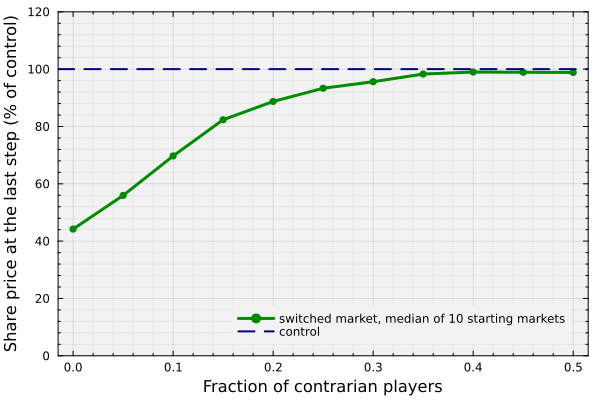

In [12]:
let

    # plot: the median over the starting markets, and the level of the control -
    q = plot(sweep.contrarian_fraction, sweep.median_percentage, lw = 3, c = color_contrarian, marker = :circle, ms = 4, markerstrokewidth = 0,
        label = "switched market, median of $(length(seeds)) starting markets",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :bottomright);
    hline!(q, [100.0], lw = 2, c = color_control, ls = :dash, label = "control");
    ylims!(q, 0.0, 120.0);
    xlabel!(q, "Fraction of contrarian players", fontsize = 18);
    ylabel!(q, "Share price at the last step (% of control)", fontsize = 18)
end

A percentage near `100` means that the share price of the switched market ends near its control. A lower percentage means that the share price of the switched market ends below its control.

___

## Summary
In this example, we ran a rule switch in a closed market and in an open market, in which traders leave and new players take their places. We then let a fraction of the players follow a contrarian rule, and compared the share price and the filled orders after the switch.

> __Key Takeaways:__
>
> * __A closed market freezes:__ We ran a rule switch in a closed market and in an open market. In the closed market, the traders run out of cash or shares, the dealer fills few orders, and the share price levels off. In the open market, the new players bring more cash and shares, and the share price keeps moving.
> * __Contrarian players act against their neighbors:__ We read the table of a contrarian rule, which gives Buy when most neighbors intend to sell and Sell when most neighbors intend to buy. After the switch, the contrarian players take the other side of the Sell orders, and the dealer keeps filling orders.
> * __The fraction of contrarian players matters:__ We repeated the rule switch for several fractions of contrarian players and many starting markets. The share price of the switched market, as a percentage of its control, shows how much of the switch the market absorbs at each fraction.

We can now change the three rules, the refresh rate, the fraction of contrarian players, the fraction of switching traders, and the starting market, and watch how the grid and the share price respond.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___